# One model - three glucose datasets


## 1. simglucose

Loads generated-datasets/simglucose/simglucose.csv (patient, time, glucose, insulin, carbs).


In [1]:
%matplotlib inline
import resource
import sys
import time
import traceback
import warnings
from pathlib import Path

import psutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    import torch
from torch import nn

np.random.seed(0)
torch.manual_seed(0)



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/liinad/Desktop/Test_glydemo/.venv/lib/python3.12/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Users/liinad/Desktop/Test_glydemo/.venv/lib/python3.12/site-packages/traitlets/config/application.py", line 1080, in launch_instance
    app.start()
  File "/Users/liinad/Desktop/Test_glydemo/.venv/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 768,

loaded simglucose (generated-datasets/simglucose/simglucose.csv)
346780 rows, 28868 windows
hypoglycaemia in the next hour: 31.6%


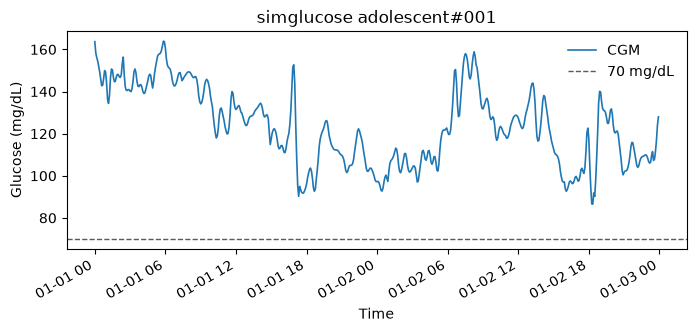

In [2]:
MEDIA = Path.cwd() / "media"
DATASETS_DIR = Path.cwd() / "generated-datasets"
MEDIA.mkdir(parents=True, exist_ok=True)

REQUIRED_COLS = ("patient", "time", "glucose", "insulin", "carbs")

# Past hour and next hour on a 5-minute grid. One window per hour.
LOOKBACK = 12
HORIZON = 12
STEP = 12
HYPO_MGDL = 70


def peak_rss_mb():
    rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    if sys.platform == "darwin":
        return round(rss / (1024 * 1024), 1)
    return round(rss / 1024, 1)


def load_dataset_table(path):
    if not path.exists():
        raise FileNotFoundError(f"Expected dataset at {path}")
    df = pd.read_csv(path, parse_dates=["time"])
    missing = set(REQUIRED_COLS) - set(df.columns)
    if missing:
        raise ValueError(f"{path}: missing columns {sorted(missing)}")
    return df


def make_windows(frame):
    """Hourly windows. Insulin and carbohydrate columns are totals per 5-minute bin."""
    rows = []
    for patient, group in frame.groupby("patient", sort=False):
        group = group.sort_values("time")
        glucose = group["glucose"].to_numpy(dtype=float)
        insulin = group["insulin"].to_numpy(dtype=float)
        carbs = group["carbs"].to_numpy(dtype=float)
        times = group["time"].to_numpy()
        span_hours = (LOOKBACK - 1) * 5 / 60
        for i in range(LOOKBACK - 1, len(group) - HORIZON, STEP):
            past = slice(i - LOOKBACK + 1, i + 1)
            future = slice(i + 1, i + 1 + HORIZON)
            g, ins, carb = glucose[past], insulin[past], carbs[past]
            ahead = glucose[future]
            if not np.isfinite(np.concatenate([g, ins, carb, ahead])).all():
                continue
            rows.append({
                "patient": patient, "time": times[i], "glucose_mean": g.mean(),
                "glucose_min": g.min(), "glucose_slope": (g[-1] - g[0]) / span_hours,
                "insulin_sum": ins.sum(), "carb_sum": carb.sum(),
                "seq": np.stack([g, ins, carb], axis=1),
                "hypo": int(ahead.min() < HYPO_MGDL),
            })
    return pd.DataFrame(rows)


sim_path = DATASETS_DIR / "simglucose" / "simglucose.csv"
sim_df = load_dataset_table(sim_path)
print(f"loaded simglucose ({sim_path.relative_to(Path.cwd())})")
sim_windows = make_windows(sim_df)
print(f"{len(sim_df)} rows, {len(sim_windows)} windows")
print(f"hypoglycaemia in the next hour: {sim_windows['hypo'].mean():.1%}")

plot_patient = sim_df["patient"].iloc[0]
shown = sim_df[sim_df["patient"] == plot_patient].dropna(subset=["glucose"]).head(576)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(shown["time"], shown["glucose"], color="C0", lw=1.2, label="CGM")
ax.axhline(HYPO_MGDL, color="0.35", ls="--", lw=1, label="70 mg/dL")
ax.set_title(f"simglucose {plot_patient}")
ax.set_xlabel("Time")
ax.set_ylabel("Glucose (mg/dL)")
ax.legend(frameon=False)
fig.autofmt_xdate()
fig.savefig(MEDIA / "simglucose-glucose.png", dpi=120, bbox_inches="tight")
plt.show()


## 2. HUPA-UCM

Loads generated-datasets/hupa/hupa.csv (same 5-minute schema). Place the preprocessed table there before running.


loaded HUPA-UCM (generated-datasets/hupa/hupa.csv)
25 patients, 309392 rows, 25746 windows
hypoglycaemia in the next hour: 11.6%


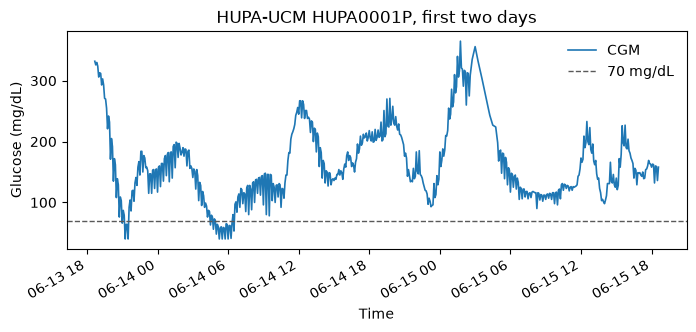

In [3]:
hupa_path = DATASETS_DIR / "hupa" / "hupa.csv"
hupa_df = load_dataset_table(hupa_path)
print(f"loaded HUPA-UCM ({hupa_path.relative_to(Path.cwd())})")
hupa_windows = make_windows(hupa_df)
print(f"{hupa_df['patient'].nunique()} patients, {len(hupa_df)} rows, {len(hupa_windows)} windows")
print(f"hypoglycaemia in the next hour: {hupa_windows['hypo'].mean():.1%}")

patient = hupa_df["patient"].iloc[0]
one = hupa_df[hupa_df["patient"] == patient].dropna(subset=["glucose"])
one = one[one["time"] < one["time"].iloc[0] + pd.Timedelta(days=2)]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(one["time"], one["glucose"], color="C0", lw=1.2, label="CGM")
ax.axhline(HYPO_MGDL, color="0.35", ls="--", lw=1, label="70 mg/dL")
ax.set_title(f"HUPA-UCM {patient}, first two days")
ax.set_xlabel("Time")
ax.set_ylabel("Glucose (mg/dL)")
ax.legend(frameon=False)
fig.autofmt_xdate()
fig.savefig(MEDIA / "hupa-ucm-patient.png", dpi=120, bbox_inches="tight")
plt.show()


## 3. ReplayBG

Loads generated-datasets/replaybg/replaybg.csv (digital-twin replay, same schema).


loaded ReplayBG (generated-datasets/replaybg/replaybg.csv)
21 patients, 190 days, 79200 rows, 6579 windows
hypoglycaemia in the next hour: 8.5%


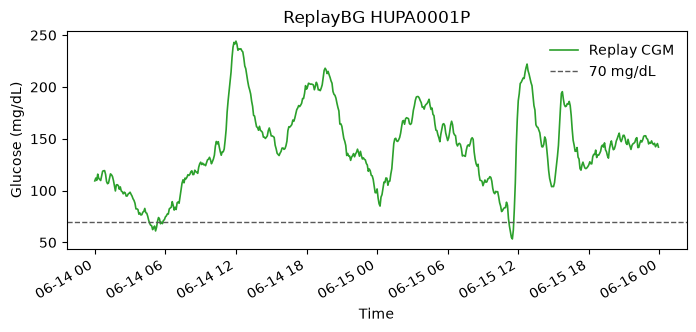

In [4]:
replay_path = DATASETS_DIR / "replaybg" / "replaybg.csv"
replay_df = load_dataset_table(replay_path)
print(f"loaded ReplayBG ({replay_path.relative_to(Path.cwd())})")
replay_windows = make_windows(replay_df)
n_days = replay_df["time"].dt.floor("D").nunique()
print(f"{replay_df['patient'].nunique()} patients, {n_days} days, {len(replay_df)} rows, {len(replay_windows)} windows")
print(f"hypoglycaemia in the next hour: {replay_windows['hypo'].mean():.1%}")

plot_patient = replay_df["patient"].iloc[0]
one = replay_df[replay_df["patient"] == plot_patient].dropna(subset=["glucose"]).head(576)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(one["time"], one["glucose"], color="C2", lw=1.2, label="Replay CGM")
ax.axhline(HYPO_MGDL, color="0.35", ls="--", lw=1, label="70 mg/dL")
ax.set_title(f"ReplayBG {plot_patient}")
ax.set_xlabel("Time")
ax.set_ylabel("Glucose (mg/dL)")
ax.legend(frameon=False)
fig.autofmt_xdate()
fig.savefig(MEDIA / "replaybg-glucose.png", dpi=120, bbox_inches="tight")
plt.show()


## 4. Model comparison (GroupKFold)

- **LR / SVC**: five summary features.
- **GRU**: 12×3 sequence, 16 units, 30 epochs, BCEWithLogitsLoss + pos_weight.
- **Transformer** (separate): nn.TransformerEncoder, 1 layer, 2 heads, 10 epochs; same loss.
- **GroupKFold(5)** on patient: each patient's windows are all in train or all in test. 


In [5]:
FEATURES = ["glucose_mean", "glucose_min", "glucose_slope", "insulin_sum", "carb_sum"]
MODELS = ["LR", "SVC", "GRU", "Transformer"]
GRU_EPOCHS = 30
TRANSFORMER_EPOCHS = 10
CHANNELS = [0, 1, 2]
BATCH_SHUFFLE_SEED = 0
BATCH_SIZE = 64
SVC_MAX_TRAIN = 30000
warnings.filterwarnings("ignore", message="The `probability` parameter was deprecated")

datasets = [
    ("simglucose", sim_windows),
    ("HUPA-UCM", hupa_windows),
    ("ReplayBG", replay_windows),
]


def to_arrays(table):
    X = np.stack(table["seq"].to_list())[:, :, CHANNELS].astype(np.float32)
    y = table["hypo"].to_numpy()
    patient_id = table["patient"].to_numpy()
    return X, y, patient_id


def shuffled_batches(n, epoch):
    g = torch.Generator()
    g.manual_seed(BATCH_SHUFFLE_SEED + epoch)
    return torch.randperm(n, generator=g)


def rss_mb():
    return round(psutil.Process().memory_info().rss / (1024 * 1024), 1)


def _result(proba, variant, train_s, infer_s, epoch_times=None, predict=None):
    mean_ep = np.nan
    if epoch_times:
        mean_ep = round(float(np.mean(epoch_times)), 3)
    return {
        "proba": proba,
        "variant": variant,
        "train_seconds": round(train_s, 2),
        "infer_seconds": round(infer_s, 3),
        "peak_memory_mb": peak_rss_mb(),
        "epoch_mean_s": mean_ep,
        "epoch_times": epoch_times or [],
        "predict": predict,
    }


def fit_lr(x_train, y_train, x_test):
    t0 = time.perf_counter()
    scaler = StandardScaler().fit(x_train)
    model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=0)
    model.fit(scaler.transform(x_train), y_train)
    train_s = time.perf_counter() - t0
    t1 = time.perf_counter()
    proba = model.predict_proba(scaler.transform(x_test))[:, 1]
    predict = lambda x: model.predict_proba(scaler.transform(x))[:, 1]
    return _result(proba, "LogisticRegression", train_s, time.perf_counter() - t1, predict=predict)


def fit_svc(x_train, y_train, x_test):
    t0 = time.perf_counter()
    scaler = StandardScaler().fit(x_train)
    if len(x_train) <= SVC_MAX_TRAIN:
        model = SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=0)
        variant = "SVC(rbf, probability=True)"
    else:
        model = CalibratedClassifierCV(LinearSVC(class_weight="balanced", random_state=0), cv=3)
        variant = "LinearSVC + CalibratedClassifierCV"
    model.fit(scaler.transform(x_train), y_train)
    train_s = time.perf_counter() - t0
    t1 = time.perf_counter()
    proba = model.predict_proba(scaler.transform(x_test))[:, 1]
    predict = lambda x: model.predict_proba(scaler.transform(x))[:, 1]
    return _result(proba, variant, train_s, time.perf_counter() - t1, predict=predict)


class GRUNet(nn.Module):
    def __init__(self, c_in=len(CHANNELS)):
        super().__init__()
        self.gru = nn.GRU(c_in, 16, batch_first=True)
        self.head = nn.Linear(16, 1)

    def forward(self, x):
        return self.head(self.gru(x)[1][-1]).squeeze(-1)


def fit_gru(seq_train, y_train, seq_test, epochs=GRU_EPOCHS, log_every=0, dataset_label=""):
    mean, std = seq_train.mean(axis=(0, 1)), seq_train.std(axis=(0, 1)) + 1e-6
    to_tensor = lambda a: torch.tensor(((a - mean) / std).astype(np.float32).tolist())
    x_train, x_test = to_tensor(seq_train), to_tensor(seq_test)
    y = torch.tensor(y_train.astype(np.float32).tolist())
    torch.manual_seed(0)
    net = GRUNet(seq_train.shape[-1])
    pos_weight = torch.tensor(float((len(y_train) - y_train.sum()) / max(y_train.sum(), 1)))
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)
    t0 = time.perf_counter()
    epoch_times = []
    for ep in range(epochs):
        ep_start = time.perf_counter()
        order = shuffled_batches(len(y), ep)
        for start in range(0, len(y), BATCH_SIZE):
            batch = order[start : start + BATCH_SIZE]
            optimizer.zero_grad()
            loss_fn(net(x_train[batch]), y[batch]).backward()
            optimizer.step()
        epoch_times.append(time.perf_counter() - ep_start)
        if log_every and (ep + 1) % log_every == 0:
            tag = f"{dataset_label} " if dataset_label else ""
            print(f"  {tag}GRU epoch {ep + 1}/{epochs}: {epoch_times[-1]:.2f}s")
    train_s = time.perf_counter() - t0
    t1 = time.perf_counter()
    with torch.no_grad():
        proba = np.array(torch.sigmoid(net(x_test)).tolist())

    def predict(a):
        with torch.no_grad():
            return np.array(torch.sigmoid(net(to_tensor(a))).tolist())

    return _result(proba, f"GRU(16), {epochs} epochs", train_s, time.perf_counter() - t1, epoch_times, predict)


class TinyTransformer(nn.Module):
    def __init__(self, c_in, t=LOOKBACK, d=32):
        super().__init__()
        self.proj = nn.Linear(c_in, d)
        pe = torch.zeros(1, t, d)
        pos = torch.arange(t, dtype=torch.float32).unsqueeze(1)
        div = torch.exp(torch.arange(0, d, 2, dtype=torch.float32) * (-np.log(10000.0) / d))
        pe[0, :, 0::2] = torch.sin(pos * div)
        pe[0, :, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe)
        layer = nn.TransformerEncoderLayer(d, nhead=2, dim_feedforward=64, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=1)
        self.head = nn.Linear(d, 1)

    def forward(self, x):
        h = self.proj(x) + self.pe
        return self.head(self.encoder(h).mean(dim=1)).squeeze(-1)


def fit_transformer(seq_train, y_train, seq_test, epochs=TRANSFORMER_EPOCHS):
    mean, std = seq_train.mean(axis=(0, 1)), seq_train.std(axis=(0, 1)) + 1e-6
    to_tensor = lambda a: torch.tensor(((a - mean) / std).astype(np.float32).tolist())
    x_train, x_test = to_tensor(seq_train), to_tensor(seq_test)
    y = torch.tensor(y_train.astype(np.float32).tolist())
    torch.manual_seed(0)
    net = TinyTransformer(seq_train.shape[-1])
    pos_weight = torch.tensor(float((len(y_train) - y_train.sum()) / max(y_train.sum(), 1)))
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)
    t0 = time.perf_counter()
    epoch_times = []
    for ep in range(epochs):
        ep_start = time.perf_counter()
        order = shuffled_batches(len(y), ep)
        for start in range(0, len(y), BATCH_SIZE):
            batch = order[start : start + BATCH_SIZE]
            optimizer.zero_grad()
            loss_fn(net(x_train[batch]), y[batch]).backward()
            optimizer.step()
        epoch_times.append(time.perf_counter() - ep_start)
    train_s = time.perf_counter() - t0
    t1 = time.perf_counter()
    with torch.no_grad():
        proba = np.array(torch.sigmoid(net(x_test)).tolist())

    def predict(a):
        with torch.no_grad():
            return np.array(torch.sigmoid(net(to_tensor(a))).tolist())

    return _result(proba, f"TinyTransformer, {epochs} epochs", train_s, time.perf_counter() - t1, epoch_times, predict)


In [6]:
cv_rows = []
epoch_time_rows = []
oof_proba = {}
gkf = GroupKFold(n_splits=5)

for name, table in datasets:
    table = table.sort_values(["patient", "time"]).reset_index(drop=True)
    oof_proba[name] = {m: np.full(len(table), np.nan) for m in MODELS}
    X, y, groups = to_arrays(table)
    feats = table[FEATURES].to_numpy()
    print(f"{name}: {X.shape[0]} windows, {len(np.unique(groups))} patients, hypo {y.mean():.1%}")
    for fold, (tr, te) in enumerate(gkf.split(X, y, groups), 1):
        for model_name in MODELS:
            try:
                if model_name == "LR":
                    out = fit_lr(feats[tr], y[tr], feats[te])
                elif model_name == "SVC":
                    out = fit_svc(feats[tr], y[tr], feats[te])
                elif model_name == "GRU":
                    out = fit_gru(X[tr], y[tr], X[te])
                else:
                    out = fit_transformer(X[tr], y[tr], X[te])
                score = average_precision_score(y[te], out["proba"])
                oof_proba[name][model_name][te] = out["proba"]
                print(f"{name} fold {fold}/5 {model_name}: AUPRC {score:.3f}")
                cv_rows.append({
                    "dataset": name,
                    "model": model_name,
                    "fold": fold,
                    "AUPRC": round(float(score), 3),
                    "train_seconds": out["train_seconds"],
                    "infer_seconds": out["infer_seconds"],
                    "peak_memory_mb": out["peak_memory_mb"],
                    "epoch_mean_s": out["epoch_mean_s"],
                    "variant": out["variant"],
                })
                if out["epoch_times"]:
                    epoch_time_rows.append({
                        "dataset": name,
                        "model": model_name,
                        "fold": fold,
                        "epoch_times_s": out["epoch_times"],
                    })
            except Exception:
                print(f"{name} fold {fold}/5 {model_name} failed:\n{traceback.format_exc()}")
                cv_rows.append({
                    "dataset": name,
                    "model": model_name,
                    "fold": fold,
                    "AUPRC": np.nan,
                    "train_seconds": np.nan,
                    "infer_seconds": np.nan,
                    "peak_memory_mb": np.nan,
                    "epoch_mean_s": np.nan,
                    "variant": "",
                })

cv_df = pd.DataFrame(cv_rows)
cv_df.to_csv(MEDIA / "auprc-folds.csv", index=False)
agg = cv_df.groupby(["dataset", "model"])["AUPRC"].agg(["mean", "std"])
summary = agg.apply(lambda r: f"{r['mean']:.3f} ± {r['std']:.3f}", axis=1).unstack("model")
summary = summary.reindex(index=[n for n, _ in datasets], columns=MODELS)
summary.to_csv(MEDIA / "auprc-results.csv")
print("\nAUPRC mean ± std (GroupKFold):\n")
print(summary.to_string())
summary


simglucose: 28868 windows, 28 patients, hypo 31.6%
simglucose fold 1/5 LR: AUPRC 0.956
simglucose fold 1/5 SVC: AUPRC 0.947
simglucose fold 1/5 GRU: AUPRC 0.963
simglucose fold 1/5 Transformer: AUPRC 0.960
simglucose fold 2/5 LR: AUPRC 0.895
simglucose fold 2/5 SVC: AUPRC 0.898
simglucose fold 2/5 GRU: AUPRC 0.920
simglucose fold 2/5 Transformer: AUPRC 0.916
simglucose fold 3/5 LR: AUPRC 0.890
simglucose fold 3/5 SVC: AUPRC 0.904
simglucose fold 3/5 GRU: AUPRC 0.922
simglucose fold 3/5 Transformer: AUPRC 0.916
simglucose fold 4/5 LR: AUPRC 0.917
simglucose fold 4/5 SVC: AUPRC 0.918
simglucose fold 4/5 GRU: AUPRC 0.940
simglucose fold 4/5 Transformer: AUPRC 0.933
simglucose fold 5/5 LR: AUPRC 0.926
simglucose fold 5/5 SVC: AUPRC 0.918
simglucose fold 5/5 GRU: AUPRC 0.943
simglucose fold 5/5 Transformer: AUPRC 0.936
HUPA-UCM: 25746 windows, 25 patients, hypo 11.6%
HUPA-UCM fold 1/5 LR: AUPRC 0.650
HUPA-UCM fold 1/5 SVC: AUPRC 0.704
HUPA-UCM fold 1/5 GRU: AUPRC 0.799
HUPA-UCM fold 1/5 Tra

model,LR,SVC,GRU,Transformer
dataset,,,,
simglucose,0.917 ± 0.027,0.917 ± 0.019,0.938 ± 0.018,0.932 ± 0.018
HUPA-UCM,0.695 ± 0.132,0.743 ± 0.130,0.830 ± 0.097,0.848 ± 0.089
ReplayBG,0.776 ± 0.060,0.805 ± 0.045,0.827 ± 0.045,0.837 ± 0.036


## 4b. Time split

Within each patient, windows are sorted by `time`. The first 80% train the model and the last 20% test it. A patient whose test tail is shorter than 24 windows is dropped. Scaling stays inside the fit and uses the training windows only. The naive score is 1 when `glucose_min` of that window is below 70 mg/dL, with no fit.


In [7]:
MIN_TEST_WINDOWS = 24
EPOCHS = {"GRU": GRU_EPOCHS, "Transformer": TRANSFORMER_EPOCHS}


def time_split(table):
    train_idx, test_idx, dropped = [], [], []
    for patient, group in table.groupby("patient", sort=False):
        group = group.sort_values("time")
        cut = int(round(0.8 * len(group)))
        tail = group.iloc[cut:]
        if len(tail) < MIN_TEST_WINDOWS:
            dropped.append(patient)
            continue
        train_idx.append(group.index[:cut].to_numpy())
        test_idx.append(tail.index.to_numpy())
    return np.concatenate(train_idx), np.concatenate(test_idx), dropped


def infer_ms(predict, x, batch=BATCH_SIZE):
    predict(x[:batch])
    t0 = time.perf_counter()
    for start in range(0, len(x), batch):
        predict(x[start : start + batch])
    return (time.perf_counter() - t0) * 1000 / len(x)


time_rows = []
cost_rows = []
for name, table in datasets:
    table = table.sort_values(["patient", "time"]).reset_index(drop=True)
    tr, te, dropped = time_split(table)
    X, y, _ = to_arrays(table)
    feats = table[FEATURES].to_numpy()
    print(
        f"{name}: train {len(tr)}, test {len(te)}, "
        f"patients {table.loc[te, 'patient'].nunique()}, "
        f"dropped {len(dropped)}, hypo {y[te].mean():.1%}"
    )
    for model_name in MODELS:
        if model_name == "LR":
            out = fit_lr(feats[tr], y[tr], feats[te])
            x_te = feats[te]
        elif model_name == "SVC":
            out = fit_svc(feats[tr], y[tr], feats[te])
            x_te = feats[te]
        elif model_name == "GRU":
            out = fit_gru(X[tr], y[tr], X[te])
            x_te = X[te]
        else:
            out = fit_transformer(X[tr], y[tr], X[te])
            x_te = X[te]
        peak = rss_mb() if model_name in EPOCHS else np.nan
        score = round(float(average_precision_score(y[te], out["proba"])), 3)
        epochs = EPOCHS.get(model_name)
        epoch_s = round(out["train_seconds"] / epochs, 3) if epochs else np.nan
        ms = round(infer_ms(out["predict"], x_te), 3)
        print(f"{name} time {model_name}: AUPRC {score:.3f}")
        time_rows.append({"dataset": name, "model": model_name, "AUPRC": score})
        cost_rows.append({
            "dataset": name,
            "model": model_name,
            "train_s": out["train_seconds"],
            "epoch_s": epoch_s,
            "peak_mb": peak,
            "infer_ms": ms,
            "AUPRC_time": score,
        })
    naive = (table.loc[te, "glucose_min"].to_numpy() < HYPO_MGDL).astype(int)
    naive_score = round(float(average_precision_score(y[te], naive)), 3)
    print(f"{name} time naive: AUPRC {naive_score:.3f}")
    time_rows.append({"dataset": name, "model": "naive", "AUPRC": naive_score})

naive_gkf = {}
for name, table in datasets:
    table = table.sort_values(["patient", "time"]).reset_index(drop=True)
    _, y, groups = to_arrays(table)
    scores = []
    for _, te in gkf.split(np.zeros(len(y)), y, groups):
        naive = (table.loc[te, "glucose_min"].to_numpy() < HYPO_MGDL).astype(int)
        scores.append(round(float(average_precision_score(y[te], naive)), 3))
    naive_gkf[name] = (float(np.mean(scores)), float(np.std(scores, ddof=1)))
    print(f"{name} GroupKFold naive: {naive_gkf[name][0]:.3f} ± {naive_gkf[name][1]:.3f}")


simglucose: train 23100, test 5768, patients 28, dropped 0, hypo 33.0%
simglucose time LR: AUPRC 0.930
simglucose time SVC: AUPRC 0.931
simglucose time GRU: AUPRC 0.948
simglucose time Transformer: AUPRC 0.943
simglucose time naive: AUPRC 0.659
HUPA-UCM: train 20595, test 5151, patients 25, dropped 0, hypo 12.4%
HUPA-UCM time LR: AUPRC 0.711
HUPA-UCM time SVC: AUPRC 0.808
HUPA-UCM time GRU: AUPRC 0.854
HUPA-UCM time Transformer: AUPRC 0.880
HUPA-UCM time naive: AUPRC 0.455
ReplayBG: train 5189, test 1295, patients 20, dropped 1, hypo 8.8%
ReplayBG time LR: AUPRC 0.786
ReplayBG time SVC: AUPRC 0.811
ReplayBG time GRU: AUPRC 0.809
ReplayBG time Transformer: AUPRC 0.854
ReplayBG time naive: AUPRC 0.442
simglucose GroupKFold naive: 0.644 ± 0.067
HUPA-UCM GroupKFold naive: 0.401 ± 0.100
ReplayBG GroupKFold naive: 0.456 ± 0.090


In [8]:
def fmt_pm(mean, std):
    return f"{mean:.3f} ± {std:.3f}"


proto_rows = []
for name, _ in datasets:
    for model_name in MODELS + ["naive"]:
        if model_name == "naive":
            mean, std = naive_gkf[name]
        else:
            sub = cv_df[(cv_df["dataset"] == name) & (cv_df["model"] == model_name)]["AUPRC"]
            mean, std = sub.mean(), sub.std()
        auprc_time = next(r["AUPRC"] for r in time_rows if r["dataset"] == name and r["model"] == model_name)
        proto_rows.append({
            "dataset": name,
            "model": model_name,
            "GroupKFold": fmt_pm(mean, std),
            "time": f"{auprc_time:.3f}",
        })
proto = pd.DataFrame(proto_rows)
proto.to_csv(MEDIA / "auprc-protocols.csv", index=False)
proto


,dataset,model,GroupKFold,time
0,simglucose,LR,0.917 ± 0.027,0.930
1,simglucose,SVC,0.917 ± 0.019,0.931
2,simglucose,GRU,0.938 ± 0.018,0.948
3,simglucose,Transformer,0.932 ± 0.018,0.943
4,simglucose,naive,0.644 ± 0.067,0.659
5,HUPA-UCM,LR,0.695 ± 0.132,0.711
6,HUPA-UCM,SVC,0.743 ± 0.130,0.808
7,HUPA-UCM,GRU,0.830 ± 0.097,0.854
8,HUPA-UCM,Transformer,0.848 ± 0.089,0.880
9,HUPA-UCM,naive,0.401 ± 0.100,0.455


## 5. Cost


In [9]:
cost = pd.DataFrame(cost_rows)[
    ["dataset", "model", "train_s", "epoch_s", "peak_mb", "infer_ms", "AUPRC_time"]
]
cost.to_csv(MEDIA / "cost.csv", index=False)
cost


,dataset,model,train_s,epoch_s,peak_mb,infer_ms,AUPRC_time
0,simglucose,LR,0.10,NaN,NaN,0.017,0.930
1,simglucose,SVC,66.34,NaN,NaN,0.761,0.931
2,simglucose,GRU,58.93,1.964,187.5,0.124,0.948
3,simglucose,Transformer,27.81,2.781,375.1,0.063,0.943
4,HUPA-UCM,LR,0.04,NaN,NaN,0.007,0.711
5,HUPA-UCM,SVC,52.14,NaN,NaN,0.714,0.808
6,HUPA-UCM,GRU,50.55,1.685,347.7,0.050,0.854
7,HUPA-UCM,Transformer,24.18,2.418,372.9,0.057,0.880
8,ReplayBG,LR,0.02,NaN,NaN,0.010,0.786
9,ReplayBG,SVC,2.47,NaN,NaN,0.127,0.811


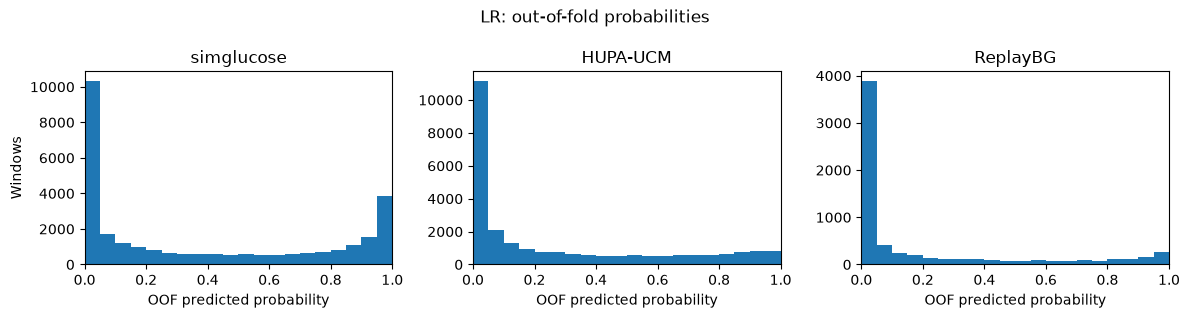

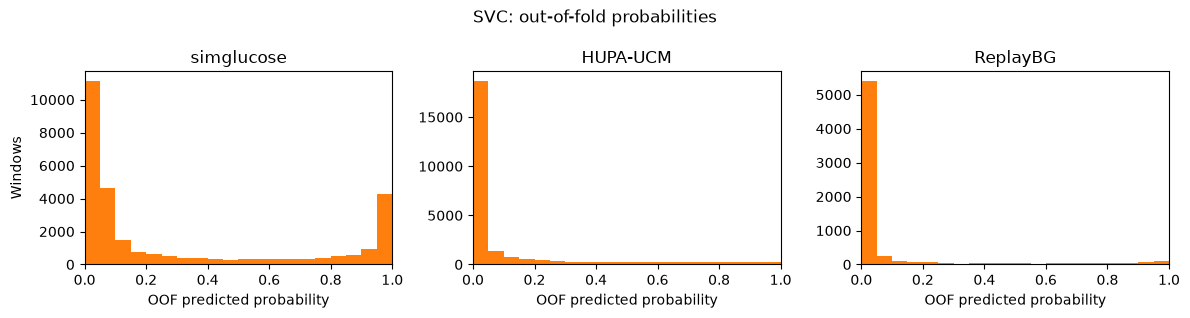

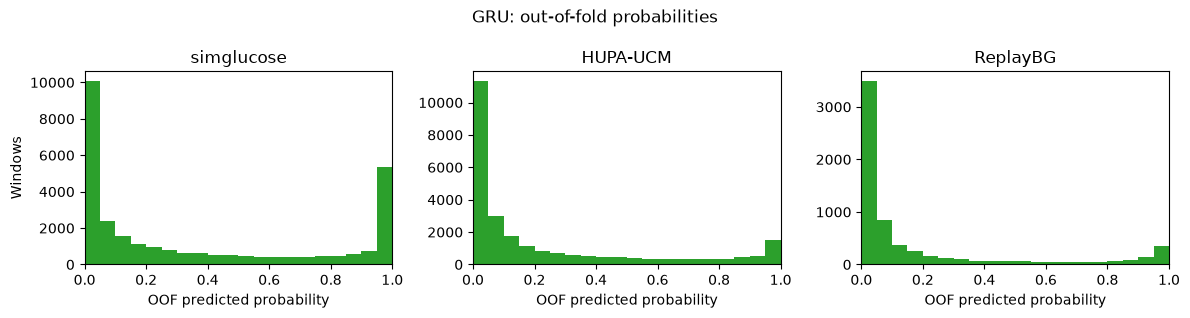

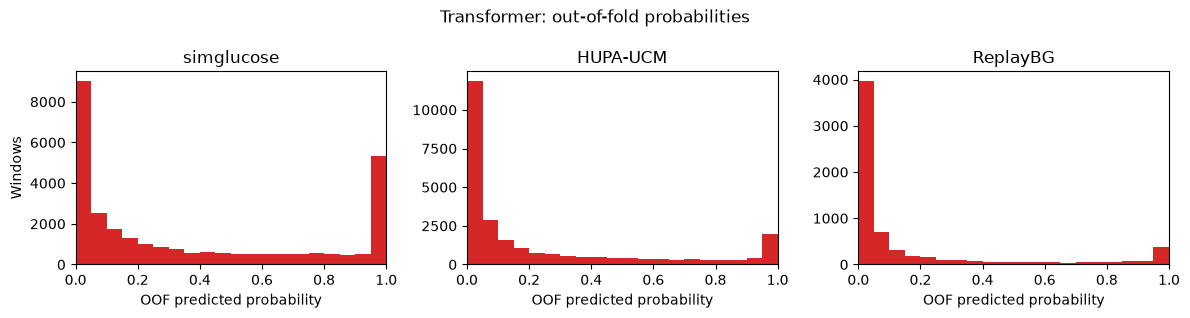

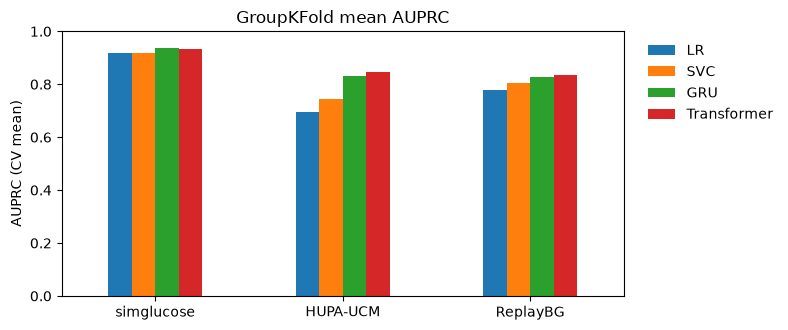

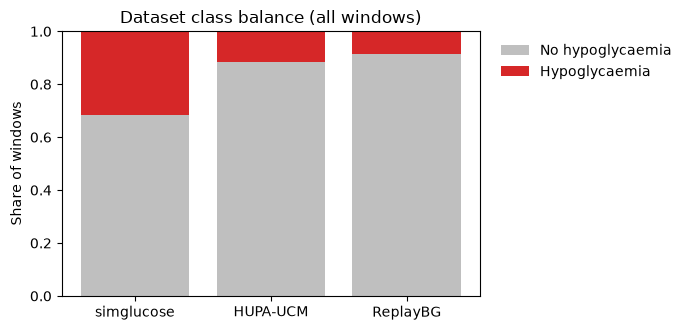

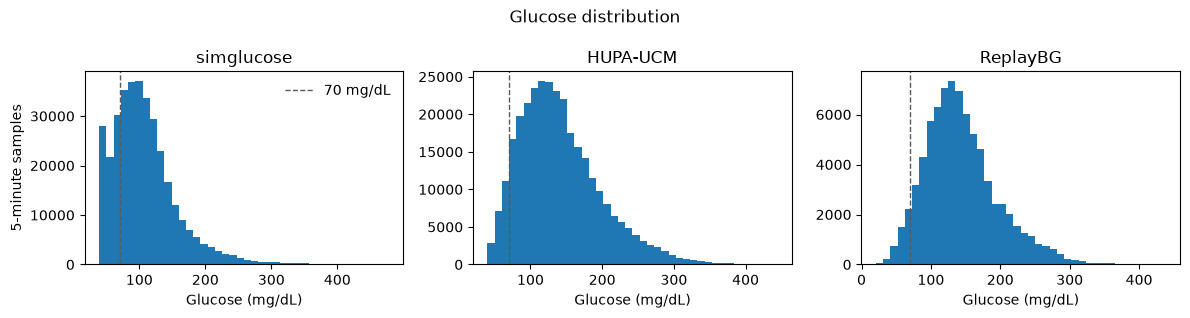

In [10]:
mean_auprc = agg["mean"].unstack("model").reindex(index=[n for n, _ in datasets], columns=MODELS)

bins = np.linspace(0, 1, 21)
colors = {"LR": "C0", "SVC": "C1", "GRU": "C2", "Transformer": "C3"}
for model_name in MODELS:
    fig, axes = plt.subplots(1, len(datasets), figsize=(4 * len(datasets), 3.2), squeeze=False)
    for ax, (dname, _) in zip(axes[0], datasets):
        p = oof_proba[dname][model_name]
        p = p[np.isfinite(p)]
        if len(p):
            ax.hist(p, bins=bins, color=colors[model_name])
        ax.set_title(dname)
        ax.set_xlabel("OOF predicted probability")
        ax.set_xlim(0, 1)
    axes[0][0].set_ylabel("Windows")
    fig.suptitle(f"{model_name}: out-of-fold probabilities")
    fig.tight_layout()
    fig.savefig(MEDIA / f"probability-histogram-{model_name.lower()}.png", dpi=120, bbox_inches="tight")
    plt.show()

order = [name for name, _ in datasets]
fig, ax = plt.subplots(figsize=(8, 3.4))
mean_auprc.plot.bar(ax=ax, rot=0, color=[colors[m] for m in MODELS])
ax.set_ylabel("AUPRC (CV mean)")
ax.set_xlabel("")
ax.set_ylim(0, 1)
ax.set_title("GroupKFold mean AUPRC")
ax.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(MEDIA / "auprc-bars.png", dpi=120, bbox_inches="tight")
plt.show()

prevalence = {name: table["hypo"].mean() for name, table in datasets}
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(order, [1 - prevalence[n] for n in order], color="0.75", label="No hypoglycaemia")
ax.bar(order, [prevalence[n] for n in order], bottom=[1 - prevalence[n] for n in order], color="C3", label="Hypoglycaemia")
ax.set_ylabel("Share of windows")
ax.set_ylim(0, 1)
ax.set_title("Dataset class balance (all windows)")
ax.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(MEDIA / "class-balance.png", dpi=120, bbox_inches="tight")
plt.show()

traces = [("simglucose", sim_df), ("HUPA-UCM", hupa_df), ("ReplayBG", replay_df)]
fig, axes = plt.subplots(1, len(traces), figsize=(4 * len(traces), 3.2), squeeze=False)
for ax, (tname, frame) in zip(axes[0], traces):
    ax.hist(frame["glucose"].dropna(), bins=40, color="C0")
    ax.axvline(HYPO_MGDL, color="0.35", ls="--", lw=1, label="70 mg/dL")
    ax.set_title(tname)
    ax.set_xlabel("Glucose (mg/dL)")
axes[0][0].set_ylabel("5-minute samples")
axes[0][0].legend(frameon=False)
fig.suptitle("Glucose distribution")
fig.tight_layout()
fig.savefig(MEDIA / "glucose-distribution.png", dpi=120, bbox_inches="tight")
plt.show()
